In [21]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# FASE 1: DATOS

In [22]:
ypf = yf.Ticker("YPF")
#ggal = yf.Ticker("GGAL")

print(ypf.options)
#print(ggal.options)

expiry = '2026-11-20'
chain = ypf.option_chain(expiry)
calls = chain.calls.copy()
puts  = chain.puts.copy()

('2026-10-16', '2026-11-20', '2027-01-15', '2027-03-19', '2027-04-16', '2027-05-21', '2027-08-20', '2027-11-19', '2028-01-21', '2029-01-19')


Se filtran strikes con openInterest ≤ 50 y bid = 0 (contratos sin actividad).
Usarlos introduciría precios teóricos o desactualizados que distorsionarían la verificación de paridad.
El precio mid (bid + ask) / 2 se usa como proxy del precio de transacción para neutralizar el efecto del spread.

In [23]:
def limpiar_chain(df):
    df = df[df["openInterest"] > 50].copy()  #liquidez
    df = df[df["bid"] > 0].copy()   #costo
    df["mid"] = (df["bid"] + df["ask"]) / 2
    return df.set_index("strike")

calls = limpiar_chain(calls)
puts = limpiar_chain(puts)

strikes_comunes = calls.index.intersection(puts.index)
calls = calls.loc[strikes_comunes]
puts  = puts.loc[strikes_comunes]

print(calls)
print(puts)

            contractSymbol             lastTradeDate  lastPrice   bid   ask  \
strike                                                                        
50.0    YPF261120C00050000 2026-10-13 19:56:38+00:00       3.86  3.70  4.10   
55.0    YPF261120C00055000 2026-10-13 15:34:10+00:00       2.00  1.45  1.75   

        change  percentChange  volume  openInterest  impliedVolatility  \
strike                                                                   
50.0      -0.5     -11.467895      57          1308           0.471197   
55.0       0.4      24.999998      17         10161           0.444830   

        inTheMoney contractSize currency  mid  
strike                                         
50.0          True      REGULAR      USD  3.9  
55.0         False      REGULAR      USD  1.6  
            contractSymbol             lastTradeDate  lastPrice  bid  ask  \
strike                                                                      
50.0    YPF261120P00050000 2026-10-13 17

In [24]:
# Precio spot (mid del último día)
S = ypf.fast_info["lastPrice"]

# Tasa libre de riesgo: T-Bill 3M desde FRED (o hardcode actual)
r = 0.0525  # ~5.25% anual, verificá en tiempo real

# Días al vencimiento

T_dias = (datetime.strptime(expiry, "%Y-%m-%d") - datetime(2026, 8, 10)).days
T = T_dias / 365

# FASE 2: PARIDAD PUT-CALL

La paridad put-call exacta C − P = S − K·e^(−rT) aplica estrictamente a opciones europeas.
Las opciones sobre ADRs en NYSE son de ejercicio americano, por lo que la relación se convierte en desigualdad:

S − K ≤ C_A − P_A ≤ S − K·e^(−rT)

El desvío positivo respecto al lado europeo es esperado: refleja la prima de ejercicio anticipado
incorporada en las puts americanas (el tenedor puede ejercer antes del vencimiento).
Esto no constituye una oportunidad de arbitraje sino una propiedad estructural del instrumento.

In [25]:
results = pd.DataFrame()
results["C"] = calls["mid"]
results["P"] = puts["mid"]
results["K"] = strikes_comunes
results["S"] = S

# Paridad europea teorica
results["Left Eur"] = results["C"] - results["P"]
results["Right Eur"] = S - results["K"] * np.exp(-r * T)
results["Desvio"] = results["Left Eur"] - results["Right Eur"]

# Paridad americana
results["Lower Am"] = S - results["K"]
results["Higher Am"] = S - results["K"] * np.exp(-r * T)
results["En rango"] = (
    (results["Left Eur"] >= results["Lower Am"]) &
    (results["Left Eur"] <= results["Higher Am"])
)

results

,C,P,K,S,Left Eur,Right Eur,Desvio,Lower Am,Higher Am,En rango
strike,,,,,,,,,,
50.0,3.9,1.95,50.0,51.790001,1.95,2.518208,-0.568208,1.790001,2.518208,True
55.0,1.6,4.70,55.0,51.790001,-3.10,-2.408972,-0.691028,-3.209999,-2.408972,True


In [26]:
results["Spread Call"] = calls["ask"] - calls["bid"]
results["Spread Put"] = puts["ask"] - puts["bid"]
results ["Costo"] = (results["Spread Call"] + results["Spread Put"])/2
results["Arbitraje"] = results["Desvio"].abs() - results["Costo"]
results["Arbitraje"]

strike
50.0    0.218208
55.0    0.341028
Name: Arbitraje, dtype: float64

Un valor de Arbitraje < 0 indica que el desvío de paridad es menor al costo de transacción observable (aproximado como el promedio de los bid-ask spreads). En ese caso el mercado es eficiente: no existe ganancia sin riesgo neta de costos.

Un valor > 0 señalaría una potencial oportunidad, aunque en la práctica también deben considerarse costos de ejecución, márgenes y restricciones de short selling.

# FASE 3 ESTRATEGIAS

Los strikes más cercanos al precio spot por debajo (K_p) y por arriba (K_c).
Este criterio replica la práctica de mercado: el protective put y el covered call se estructuran típicamente near-the-money para maximizar costo/protección.

In [27]:
S0    = S             # precio de entrada al subyacente
atm = min(strikes_comunes, key=lambda k: abs(k - S))
K_p = max([k for k in strikes_comunes if k <= atm])  # OTM put (≤ ATM)
K_c = min([k for k in strikes_comunes if k >= atm])
prem_p = results["P"][50]          # prima put (mid)
prem_c = results["C"][55]          # prima call (mid)

rango_ST = np.linspace(S0 * 0.6, S0 * 1.4, 500)

def payoff_protective_put(ST):
    stock  = ST - S0
    put_po = np.maximum(K_p - ST, 0)
    return stock + put_po - prem_p    # neto de prima

def payoff_covered_call(ST):
    stock   = ST - S0
    call_po = -np.maximum(ST - K_c, 0)
    return stock + call_po + prem_c   # recibís la prima

def payoff_collar(ST):
    stock   = ST - S0
    put_po  = np.maximum(K_p - ST, 0)
    call_po = -np.maximum(ST - K_c, 0)
    return stock + put_po + call_po - prem_p + prem_c

In [28]:
# Protective Put
perdida_max_put  = K_p - S0 - prem_p        # piso: constante para ST ≤ K_p
ganancia_max_put = float("inf")              # ilimitada
# Covered Call
ganancia_max_call = K_c - S0 + prem_c       # techo: constante para ST ≥ K_c
perdida_max_call  = prem_c - S0             # ST → 0
print(f"Put Perd. max: {perdida_max_put:.2f}, Gan. max: ilimitada")
print(f"Call Perd. max: {perdida_max_call:.2f}, Gan. max: {ganancia_max_call:.2f}")

perdida_max_collar  = K_p - S0 - prem_p + prem_c
ganancia_max_collar = K_c - S0 - prem_p + prem_c
print(f"Perd. total max: {perdida_max_collar:.2f}, Gan. total max: {ganancia_max_collar:.2f}")

break_even_put = S0 + prem_p
break_even_call = S0 - prem_c
break_even_collar = S0 + prem_p - prem_c

be = {
    "Protective Put": break_even_put,
    "Covered Call":   break_even_call,
    "Collar":         break_even_collar,
}

for nombre, valor in be.items():
    print(f"{nombre:20s}  BE = {valor:.2f}")
    
resumen = pd.DataFrame({"Put Perd. max": perdida_max_put, "Gan. max": "ilimitada",
                        "Call Perd. max": perdida_max_call, "Gan. max": ganancia_max_call,
                        "Perd. total max": perdida_max_collar, "Gan. total max": ganancia_max_collar},
                       be
                       )

Put Perd. max: -3.74, Gan. max: ilimitada
Call Perd. max: -50.19, Gan. max: -0.19
Perd. total max: -2.14, Gan. total max: -2.14
Protective Put        BE = 53.74
Covered Call          BE = 50.19
Collar                BE = 52.14


- Protective Put: actúa como un seguro sobre la posición larga. La prima pagada es el costo máximo de la cobertura; a cambio, el upside permanece ilimitado.

- Covered Call: genera ingreso inmediato (la prima cobrada) a cambio de resignar el upside por encima de K_c. Estrategia frecuente en carteras con expectativa neutral a levemente alcista.

- Collar: combina ambas. Acota pérdida y ganancia dentro de un rango definido. Puede estructurarse con costo neto cercano a cero si prem_c ≈ prem_p (collar de financiamiento).

# FASE 4: DIAGRAMAS

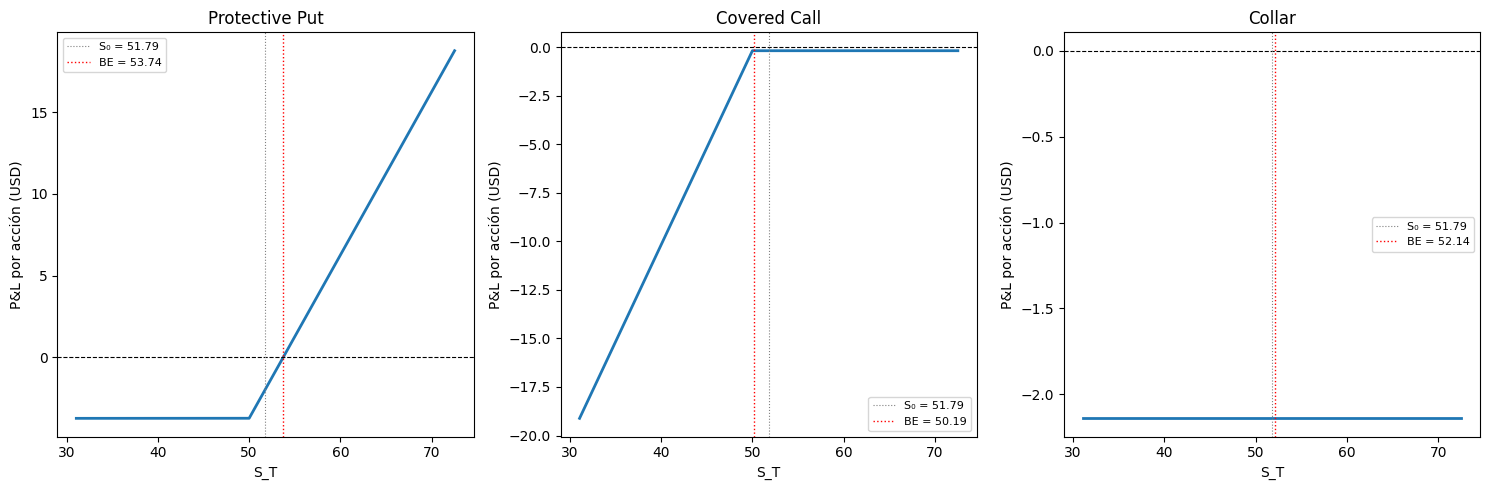

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

estrategias = [
    ("Protective Put", payoff_protective_put),
    ("Covered Call",   payoff_covered_call),
    ("Collar",         payoff_collar),
]

be_values = [break_even_put, break_even_call, break_even_collar]

for ax, (nombre, fn), be_val in zip(axes, estrategias, be_values):
    pnl = fn(rango_ST)
    ax.plot(rango_ST, pnl, lw=2)
    ax.axhline(0, color="black", lw=0.8, ls="--")
    ax.axvline(S0, color="gray", lw=0.8, ls=":", label=f"S₀ = {S0:.2f}")
    ax.axvline(be_val, color="red", lw=1, ls=":", label=f"BE = {be_val:.2f}")
    ax.legend(fontsize=8)
    ax.set_title(nombre)
    ax.set_xlabel("S_T")
    ax.set_ylabel("P&L por acción (USD)")

plt.tight_layout()
plt.savefig("payoff_strategies.png", dpi=150)

In [30]:
payoff_df = pd.DataFrame({
    "S_T": rango_ST,
    "Protective Put": payoff_protective_put(rango_ST),
    "Covered Call":   payoff_covered_call(rango_ST),
    "Collar":         payoff_collar(rango_ST),
})
payoff_df.to_csv("payoffs_export.csv", index=False)

results.to_csv("resultados.csv", index=False)

resumen.to_csv("resumen.csv", index=False)